# COVID-19 Global Impact Dashboard

## 1. Project Overview
This project analyzes global COVID-19 data to identify trends in cases, deaths, and vaccination progress across different countries and time periods. Python is used for data cleaning, analysis, and visualization.

## 2. Objectives
- To explore the global COVID-19 dataset.
- To clean missing values and duplicate records.
- To analyze COVID-19 cases and deaths across countries.
- To calculate 7-day rolling averages and case fatality rates.
- To compare COVID-19 trends using population-based metrics.
- To study vaccination progress where data is available.
- To create visualizations and identify key insights.
- To prepare findings for a dashboard and executive summary.

## 3. Project Workflow
1. Import libraries
2. Load the dataset
3. Explore the dataset
4. Check and handle missing values
5. Clean the dataset
6. Perform exploratory data analysis
7. Calculate key metrics
8. Visualize COVID-19 trends
9. Identify key insights
10. Prepare the final report

## 1.Data Loading and Importing Libraries

In [1]:
# 1.1 Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
# 1.2 Load The Dataset
df = pd.read_csv(
    '/content/owid-covid-data.csv'
)

print("Dataset loaded successfully!")


Dataset loaded successfully!


## 2. Data Exploration and Quality Assessment

In [4]:

# Display the first 5 rows
print("1. First 5 Rows:")
print(df.head())

# Display the last 5 rows
print("\n2. Last 5 Rows:")
print(df.tail())

# Dataset shape
print("\n3. Dataset Shape (Rows, Columns):")
print(df.shape)

# Number of rows and columns
print("\n4. Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Column names
print("\n5. Column Names:")
print(df.columns.tolist())

# Dataset information
print("\n6. Dataset Information:")
df.info()



1. First 5 Rows:
  iso_code continent     location        date  total_cases  new_cases  \
0      AFG      Asia  Afghanistan  2020-01-03          NaN        0.0   
1      AFG      Asia  Afghanistan  2020-01-04          NaN        0.0   
2      AFG      Asia  Afghanistan  2020-01-05          NaN        0.0   
3      AFG      Asia  Afghanistan  2020-01-06          NaN        0.0   
4      AFG      Asia  Afghanistan  2020-01-07          NaN        0.0   

   new_cases_smoothed  total_deaths  new_deaths  new_deaths_smoothed  ...  \
0                 NaN           NaN         0.0                  NaN  ...   
1                 NaN           NaN         0.0                  NaN  ...   
2                 NaN           NaN         0.0                  NaN  ...   
3                 NaN           NaN         0.0                  NaN  ...   
4                 NaN           NaN         0.0                  NaN  ...   

   male_smokers  handwashing_facilities  hospital_beds_per_thousand  \
0         

In [5]:
# Statistical summary
print("\n7. Statistical Summary:")
print(df.describe())

# Missing values
print("\n8. Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\n9. Duplicate Records:")
print(df.duplicated().sum())

# Unique locations
print("\n10. Number of Unique Locations:")
print(df["location"].nunique())

# Date range
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("\n11. Date Range:")
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())



7. Statistical Summary:
        total_cases     new_cases  new_cases_smoothed  total_deaths  \
count  3.120880e+05  3.404570e+05        3.391980e+05  2.905010e+05   
mean   6.683354e+06  9.601634e+03        9.637066e+03  8.602180e+04   
std    4.068903e+07  1.102769e+05        9.447784e+04  4.398873e+05   
min    1.000000e+00  0.000000e+00        0.000000e+00  1.000000e+00   
25%    8.090000e+03  0.000000e+00        2.860000e-01  1.270000e+02   
50%    7.020500e+04  2.000000e+00        2.485700e+01  1.328000e+03   
75%    7.409558e+05  2.640000e+02        4.978570e+02  1.192200e+04   
max    7.714071e+08  8.401961e+06        6.402036e+06  6.972139e+06   

          new_deaths  new_deaths_smoothed  total_cases_per_million  \
count  340511.000000        339281.000000            312088.000000   
mean       85.511055            85.817071            101749.851259   
std       613.687971           559.130004            151265.689121   
min         0.000000             0.000000              

## 3. Data Cleaning and Preprocessing

In [6]:
# 3.1 Create a Copy of the Dataset
df_clean = df.copy()
print("Original Dataset Shape:", df.shape)

# 3.2 Convert Date Column to Datetime Format
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

# 3.3 Remove Duplicate Records
df_clean = df_clean.drop_duplicates()

# 3.4 Remove Rows with Missing Dates and Locations
df_clean = df_clean.dropna(subset=["date", "location"])

# 3.5 Sort Data by Location and Date
df_clean = df_clean.sort_values(
    ["location", "date"]
).reset_index(drop=True)

# 3.6 Check Missing Values in Important Columns
columns = [
    "total_cases",
    "new_cases",
    "total_deaths",
    "new_deaths",
    "population"
]

print("\nMissing Values in Important Columns:")

for col in columns:
    if col in df_clean.columns:
        print(col, ":", df_clean[col].isnull().sum())

# 3.7 Display the Preprocessed Dataset
print("\nPreprocessing Completed Successfully!")
print("Preprocessed Dataset Shape:", df_clean.shape)

print("\nFirst 5 Rows:")
print(df_clean.head())

Original Dataset Shape: (350085, 67)

Missing Values in Important Columns:
total_cases : 37997
new_cases : 9628
total_deaths : 59584
new_deaths : 9574
population : 0

Preprocessing Completed Successfully!
Preprocessed Dataset Shape: (350085, 67)

First 5 Rows:
  iso_code continent     location       date  total_cases  new_cases  \
0      AFG      Asia  Afghanistan 2020-01-03          NaN        0.0   
1      AFG      Asia  Afghanistan 2020-01-04          NaN        0.0   
2      AFG      Asia  Afghanistan 2020-01-05          NaN        0.0   
3      AFG      Asia  Afghanistan 2020-01-06          NaN        0.0   
4      AFG      Asia  Afghanistan 2020-01-07          NaN        0.0   

   new_cases_smoothed  total_deaths  new_deaths  new_deaths_smoothed  ...  \
0                 NaN           NaN         0.0                  NaN  ...   
1                 NaN           NaN         0.0                  NaN  ...   
2                 NaN           NaN         0.0                  NaN  ...  

## 4. Exploratory Data Analysis(EDA)

### 4.1 Top 10 Locations with the Highest Total COVID-19 Cases

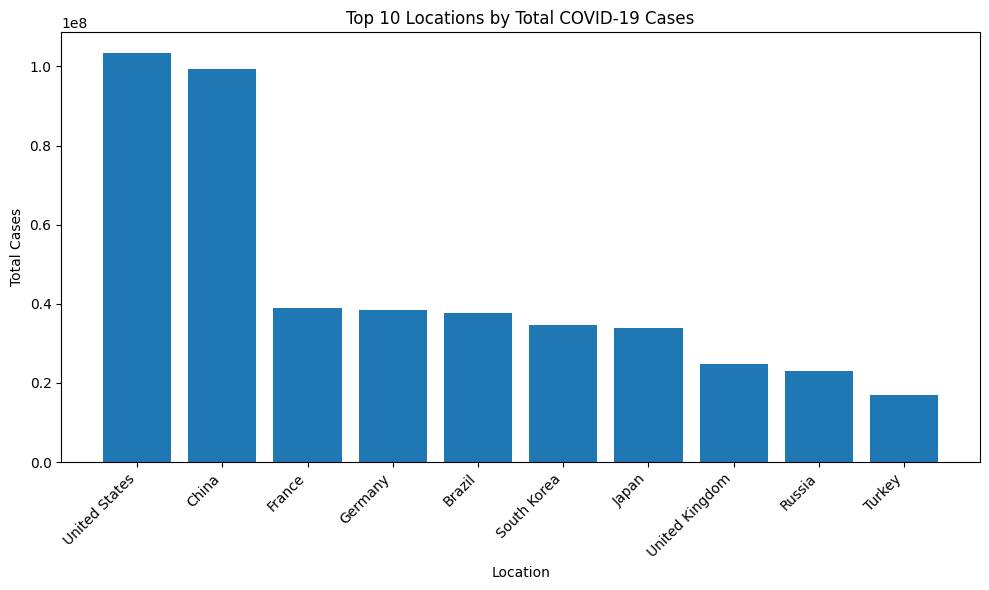

In [7]:
# 4.1 Top 10 Locations with the Highest Total COVID-19 Cases

latest_data = df_clean.sort_values("date").groupby(
    "location"
).tail(1)

latest_data = latest_data.dropna(subset=["total_cases"])

latest_data = latest_data[
    ~latest_data["location"].isin(["World", "European Union"])
]

top_cases = latest_data.nlargest(10, "total_cases")

plt.figure(figsize=(10, 6))
plt.bar(top_cases["location"], top_cases["total_cases"])
plt.title("Top 10 Locations by Total COVID-19 Cases")
plt.xlabel("Location")
plt.ylabel("Total Cases")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### 4.2 Top 10 Locations with the Highest Total COVID-19 Deaths

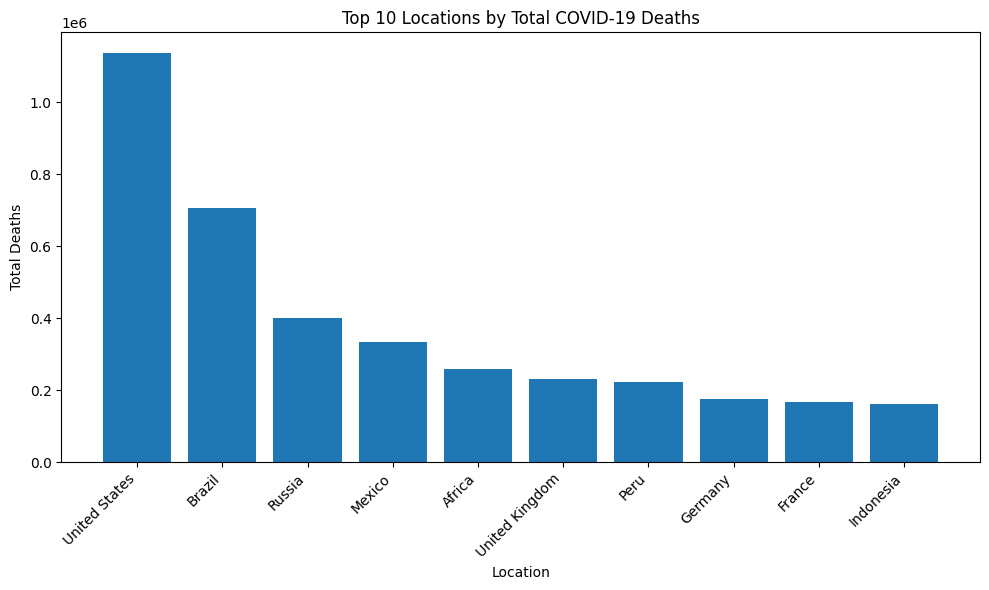

In [8]:
# 4.2 Top 10 Locations with the Highest Total COVID-19 Deaths

top_deaths = latest_data.dropna(
    subset=["total_deaths"]
).nlargest(10, "total_deaths")

plt.figure(figsize=(10, 6))
plt.bar(top_deaths["location"], top_deaths["total_deaths"])
plt.title("Top 10 Locations by Total COVID-19 Deaths")
plt.xlabel("Location")
plt.ylabel("Total Deaths")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()




### 4.3 Daily New COVID-19 Cases in India

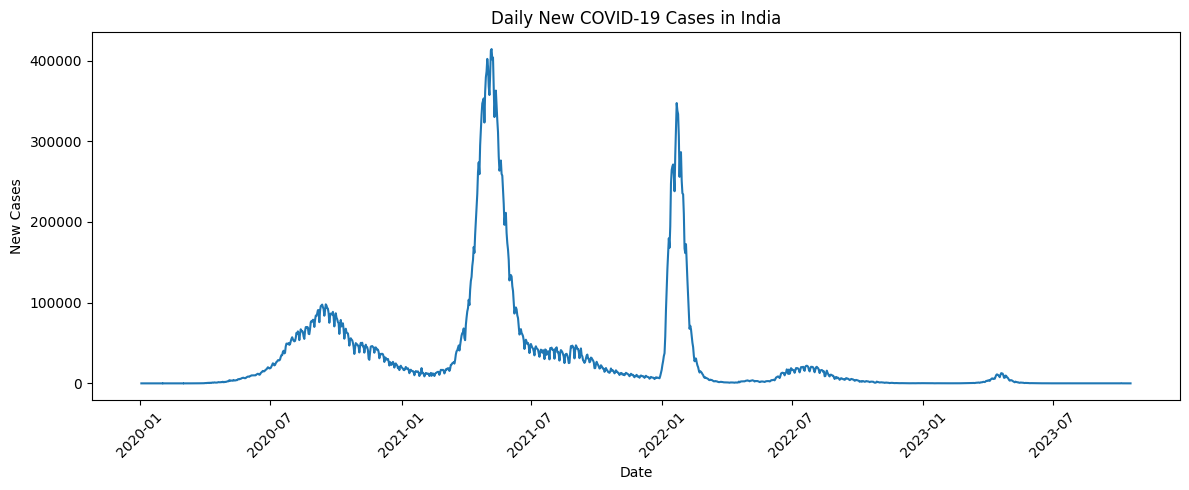

In [9]:
# 4.3 Daily New COVID-19 Cases in India

india = df_clean[df_clean["location"] == "India"].copy()
india = india.sort_values("date")

plt.figure(figsize=(12, 5))
plt.plot(india["date"], india["new_cases"])
plt.title("Daily New COVID-19 Cases in India")
plt.xlabel("Date")
plt.ylabel("New Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




### 4.4 Daily New COVID-19 Deaths in India

Text(0.5, 1.0, 'Daily New COVID-19 Death')

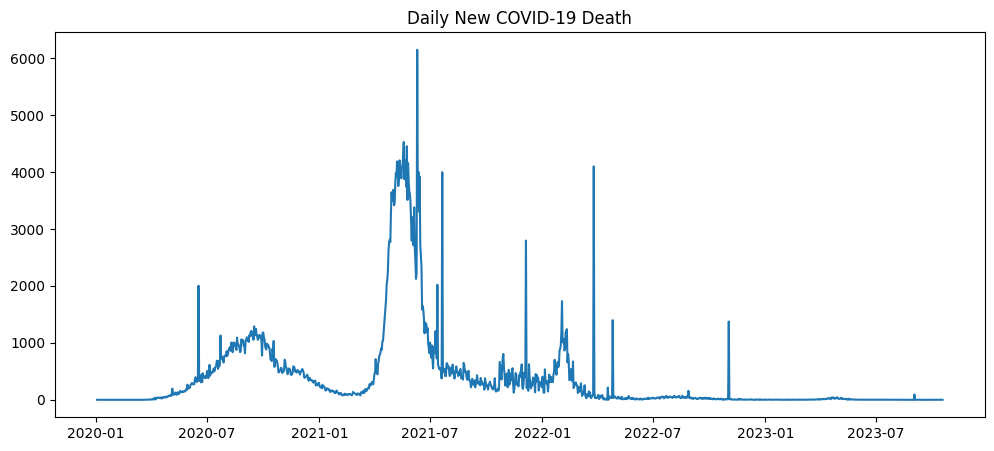

In [10]:
# 4.4 Daily New COVID-19 Deaths in India

plt.figure(figsize=(12, 5))
plt.plot(india["date"], india["new_deaths"])
plt.title("Daily New COVID-19 Death")

### 4.5 Total COVID-19 Cases per Million People in India

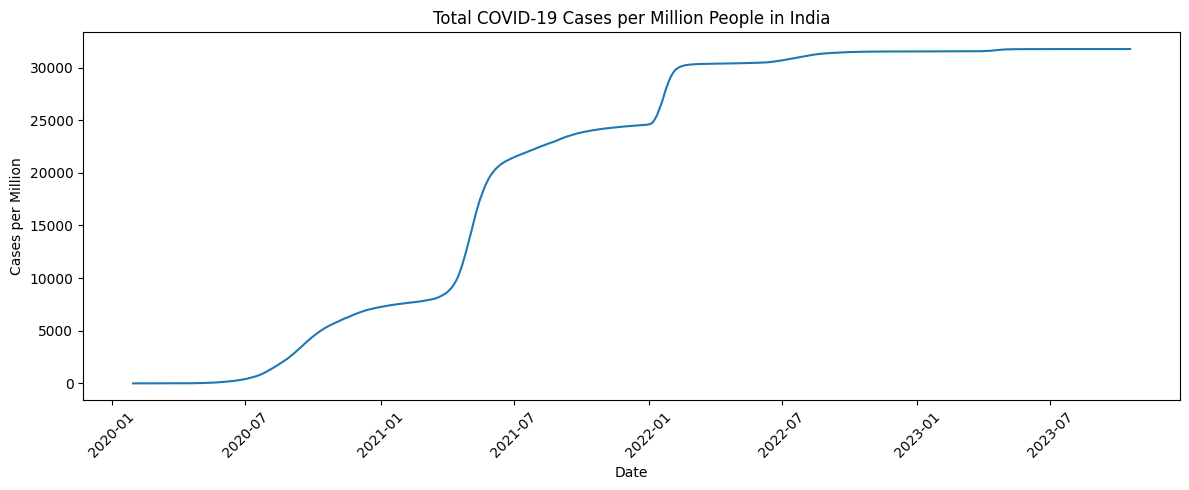

In [11]:
# 4.5 Total COVID-19 Cases per Million People in India

if "total_cases_per_million" in india.columns:
    plt.figure(figsize=(12, 5))
    plt.plot(india["date"], india["total_cases_per_million"])
    plt.title("Total COVID-19 Cases per Million People in India")
    plt.xlabel("Date")
    plt.ylabel("Cases per Million")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


### 4.6 Case Fatality Rate in India

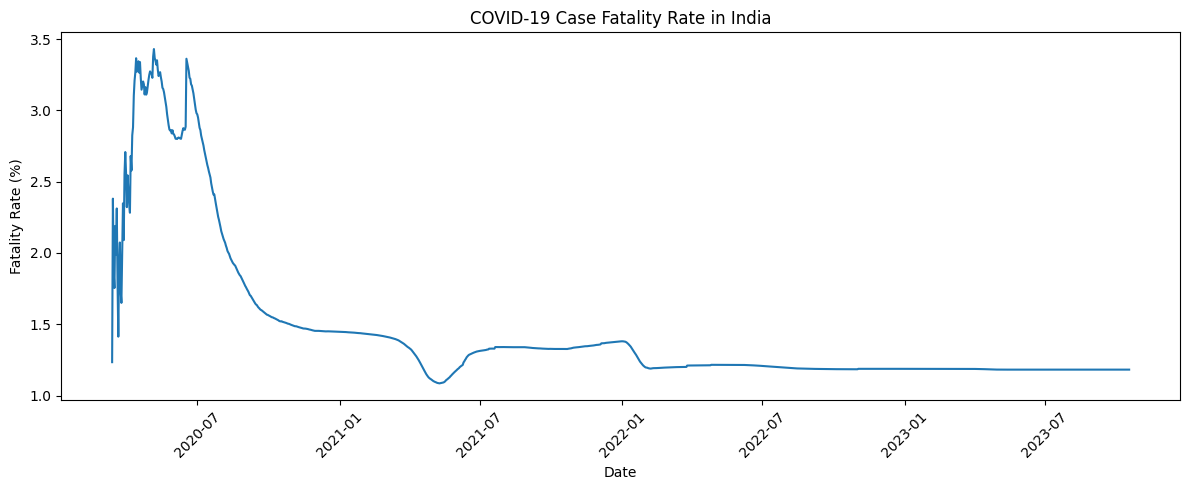

In [12]:
# 4.6 Case Fatality Rate in India

india["case_fatality_rate"] = (
    india["total_deaths"] / india["total_cases"]
) * 100

india["case_fatality_rate"] = india[
    "case_fatality_rate"
].replace([np.inf, -np.inf], np.nan)

plt.figure(figsize=(12, 5))
plt.plot(india["date"], india["case_fatality_rate"])
plt.title("COVID-19 Case Fatality Rate in India")
plt.xlabel("Date")
plt.ylabel("Fatality Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Key Findings and Insights

### 5.1 COVID-19 Cases Across Different Locations

In [18]:
# 5.1 COVID-19 Cases Across Different Locations

latest_data = df_clean.sort_values("date").groupby(
    "location"
).tail(1)

latest_data = latest_data[
    ~latest_data["location"].isin(["World", "European Union"])
]

top_cases = latest_data.dropna(
    subset=["total_cases"]
).nlargest(5, "total_cases")

print("Top 5 Locations by Total COVID-19 Cases:")
print(top_cases[["location", "total_cases"]].to_string(index=False))




Top 5 Locations by Total COVID-19 Cases:
     location  total_cases
United States  103436829.0
        China   99315684.0
       France   38997490.0
      Germany   38437756.0
       Brazil   37721749.0


### 5.2 Locations with the Highest Reported Deaths

In [19]:
# 5.2 Locations with the Highest Reported Deaths

top_deaths = latest_data.dropna(
    subset=["total_deaths"]
).nlargest(5, "total_deaths")

print("\nTop 5 Locations by Total COVID-19 Deaths:")
print(top_deaths[["location", "total_deaths"]].to_string(index=False))





Top 5 Locations by Total COVID-19 Deaths:
     location  total_deaths
United States     1136920.0
       Brazil      704659.0
       Russia      400102.0
       Mexico      334699.0
       Africa      259023.0


### 5.3 Daily COVID-19 Cases in India

In [20]:
# 5.3 Daily COVID-19 Cases in India

india = df_clean[df_clean["location"] == "India"].copy()

print("\nIndia - Highest Daily New Cases:")
print(india["new_cases"].max())

print("\nIndia - Average Daily New Cases:")
print(india["new_cases"].mean())





India - Highest Daily New Cases:
414188.0

India - Average Daily New Cases:
32561.752532561506


### 5.4 Daily COVID-19 Death Trends in India

In [21]:
# 5.4 Daily COVID-19 Death Trends in India

print("\nIndia - Highest Daily New Deaths:")
print(india["new_deaths"].max())

print("\nIndia - Average Daily New Deaths:")
print(india["new_deaths"].mean())





India - Highest Daily New Deaths:
6148.0

India - Average Daily New Deaths:
384.142238267148


### 5.5 COVID-19 Cases per Million People

In [22]:
# 5.5 COVID-19 Cases per Million People

if "total_cases_per_million" in india.columns:
    print("\nLatest Total Cases per Million in India:")
    print(india.sort_values("date")["total_cases_per_million"].dropna().tail(1))





Latest Total Cases per Million in India:
141157    31753.063
Name: total_cases_per_million, dtype: float64


### 5.6 Case Fatality Rate Analysis

In [26]:
latest_india = india.sort_values("date").iloc[-1]

total_cases = latest_india["total_cases"]
total_deaths = latest_india["total_deaths"]

if pd.notna(total_cases) and pd.notna(total_deaths) and total_cases > 0:
    fatality_rate = (total_deaths / total_cases) * 100

    print("Latest Date:", latest_india["date"].date())
    print("Total Cases:", total_cases)
    print("Total Deaths:", total_deaths)
    print("Latest Case Fatality Rate in India:", round(fatality_rate, 2), "%")
else:
    print("Required data is missing. Finding the latest available record...")

    valid_data = india.dropna(
        subset=["total_cases", "total_deaths"]
    )

    valid_data = valid_data[valid_data["total_cases"] > 0]

    if not valid_data.empty:
        latest_india = valid_data.sort_values("date").iloc[-1]

        fatality_rate = (
            latest_india["total_deaths"] /
            latest_india["total_cases"]
        ) * 100

        print("Latest Available Date:", latest_india["date"].date())
        print("Latest Case Fatality Rate in India:", round(fatality_rate, 2), "%")
    else:
        print("No valid data available to calculate the fatality rate.")

Required data is missing. Finding the latest available record...
Latest Available Date: 2023-10-18
Latest Case Fatality Rate in India: 1.18 %


## 6. Conclusion
### 6.1 Project Summary
The COVID-19 Global Impact Dashboard project analyzes the global impact of COVID-19 using the Our World in Data dataset. Python and its libraries were used to preprocess the dataset, analyze COVID-19 cases and deaths, and visualize the trends over time.
### 6.2 Major Observations
- Total COVID-19 cases: The graph shows that the United States has the highest reported total cases among the displayed locations, followed by China.
- Total COVID-19 deaths: The United States has the highest reported deaths in the displayed comparison, followed by Brazil.
- Daily new cases in India: The graph shows major peaks in 2020 and 2021, with the largest peak appearing in 2021.
- Daily new deaths in India: The highest peak appears around 2021, with smaller peaks in later periods.
- Cases per million in India: The cumulative cases per million increased over time and then became relatively stable.
- Case fatality rate in India: The rate declined from its early high values and remained around 1.2% toward the end of the displayed period.
### 6.3 Final Conclusion
The project demonstrates how data analytics and visualization can help understand the spread and impact of COVID-19 across different locations and time periods. The analysis highlights changes in reported cases, deaths, and case fatality rates. These findings show the importance of data preprocessing, exploratory data analysis, and visualization in extracting meaningful insights from real-world datasets.


## 7. Key Findings and Insights
### 7.1 Global COVID-19 Impact
The comparison charts highlight differences in reported COVID-19 cases and deaths across locations.
### 7.2 COVID-19 Trends in India
The daily cases and deaths graphs show several waves of infection, with a particularly prominent rise during 2021.
### 7.3 Case Fatality Rate
The case fatality rate graph shows a general decline over the displayed period, followed by relative stability.
### 7.4 Overall Insight
Visualizing COVID-19 data makes it easier to identify peaks, compare locations, and understand changes over time.
Note: These findings describe the graphs you shared. Since the dataset contains reported figures, the graphs alone cannot explain why the peaks occurred or establish the accuracy of reporting in each location.

## 8. Save the Preprocessed Dataset

### 8.1 Export the Cleaned Dataset to CSV

In [27]:
df_clean.to_csv("covid19_cleaned_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


### 8.2 Download the Cleaned Dataset

In [28]:
from google.colab import files

files.download("covid19_cleaned_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>